In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("/content/house_prices.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(187531, 21)


In [5]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  object 
 2   Description        184508 non-null  object 
 3   Amount(in rupees)  187531 non-null  object 
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  object 
 6   Carpet Area        106858 non-null  object 
 7   Status             186916 non-null  object 
 8   Floor              180454 non-null  object 
 9   Transaction        187448 non-null  object 
 10  Furnishing         184634 non-null  object 
 11  facing             117298 non-null  object 
 12  overlooking        106095 non-null  object 
 13  Society            77853 non-null   object 
 14  Bathroom           186703 non-null  object 
 15  Balcony            138596 non-null  object 
 16  Ca

In [7]:
df.isnull().sum()

,0
Index,0
Title,0
Description,3023
Amount(in rupees),0
Price (in rupees),17665
location,0
Carpet Area,80673
Status,615
Floor,7077
Transaction,83


In [8]:
df=df.drop_duplicates()
df=df.fillna(df.select_dtypes("number").median())

In [9]:
df=df.drop_duplicates()
df=df.fillna(df.select_dtypes("category").mode())

In [10]:
df.isnull().sum()

,0
Index,0
Title,0
Description,3023
Amount(in rupees),0
Price (in rupees),0
location,0
Carpet Area,80673
Status,615
Floor,7077
Transaction,83


In [11]:
# Select required columns
data = df[['Carpet Area', 'Amount(in rupees)']].copy()

# Extract numerical carpet area
data['Carpet Area'] = pd.to_numeric(
    data['Carpet Area'].str.extract(r'([\d.]+)')[0],
    errors='coerce'
)

# Convert house prices into rupees
def convert_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower().replace(',', '')

    if 'lac' in value:
        return float(value.replace('lac', '').strip()) * 100000

    elif 'cr' in value:
        return float(value.replace('cr', '').strip()) * 10000000

    else:
        return np.nan

data['Amount(in rupees)'] = data['Amount(in rupees)'].apply(convert_price)

# Remove missing and invalid values
data = data.dropna()

data = data[
    (data['Carpet Area'] >= 100) &
    (data['Carpet Area'] <= 10000) &
    (data['Amount(in rupees)'] >= 100000) &
    (data['Amount(in rupees)'] <= 1000000000)
]

print(data.head())
print("Cleaned dataset size:", data.shape)

   Carpet Area  Amount(in rupees)
0        500.0          4200000.0
1        473.0          9800000.0
2        779.0         14000000.0
3        530.0          2500000.0
4        635.0         16000000.0
Cleaned dataset size: (98960, 2)


In [12]:
X = data[['Carpet Area']]
y = data['Amount(in rupees)']

print("Feature: Carpet Area")
print("Target: Amount in rupees")

Feature: Carpet Area
Target: Amount in rupees


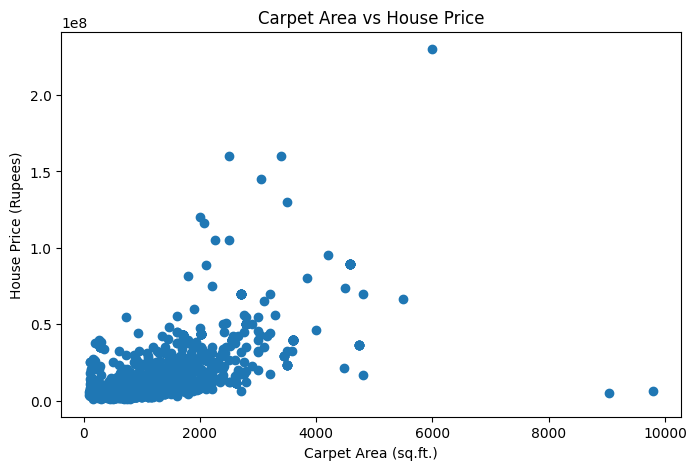

In [13]:
plt.figure(figsize=(8,5))

plt.scatter(X['Carpet Area'].sample(
    min(3000, len(X)), random_state=42
), y.loc[X['Carpet Area'].sample(
    min(3000, len(X)), random_state=42
).index])

plt.xlabel("Carpet Area (sq.ft.)")
plt.ylabel("House Price (Rupees)")
plt.title("Carpet Area vs House Price")
plt.show()

In [14]:
correlation = data['Carpet Area'].corr(data['Amount(in rupees)'])

print("Correlation:", correlation)

if correlation > 0:
    print("Positive Relationship")
elif correlation < 0:
    print("Negative Relationship")
else:
    print("Zero Relationship")

Correlation: 0.6924820240837838
Positive Relationship


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 79168
Testing records: 19792


In [16]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Model trained successfully!
Coefficient: 14224.008689921011
Intercept: -3971269.6193702873


In [17]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0     3600000.0     6.696737e+06
1     6500000.0    -2.477749e+06
2     5810000.0     9.143266e+06
3    26800000.0     2.376555e+07
4     4200000.0     7.123457e+06
5    21100000.0     2.030911e+07
6    21000000.0     1.594234e+07
7     4500000.0     8.261378e+06
8     8500000.0     1.736474e+07
9     2300000.0     3.069615e+06


In [18]:
mse = mean_squared_error(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Squared Error: 117655964280711.5
Mean Absolute Error: 6053359.701395465
R2 Score: 0.48068593430620854


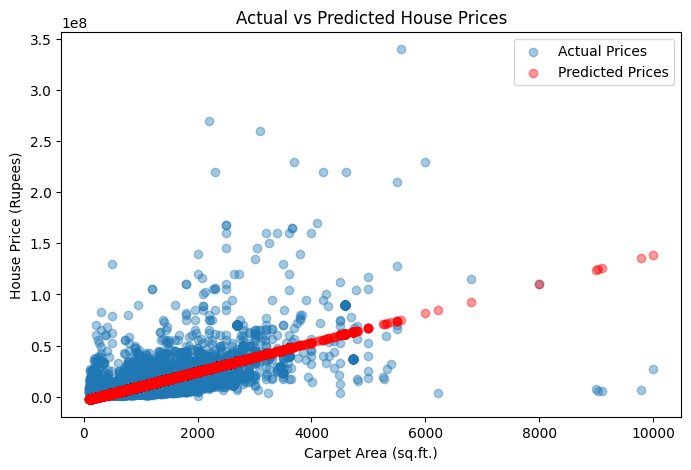

In [19]:
plt.figure(figsize=(8,5))

plt.scatter(X_test, y_test, alpha=0.4, label="Actual Prices")

plt.scatter(X_test, y_pred, color='red',
            alpha=0.4, label="Predicted Prices")

plt.xlabel("Carpet Area (sq.ft.)")
plt.ylabel("House Price (Rupees)")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.show()